# JS08 - Lab Assignment 2: HDBSCAN on the Iris Dataset

In [1]:
!pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)
y_true = iris.target
print(X.shape)

(150, 4)


## 1. Clustering with HDBSCAN

In [2]:
hdb = hdbscan.HDBSCAN(min_cluster_size=10)
labels = hdb.fit_predict(X)

## 2. Results: Number of Clusters and Noise

In [3]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())

print('Number of clusters formed:', n_clusters)
print('Number of noise points   :', n_noise, f'({n_noise / len(labels):.1%})')
print('Adjusted Rand Index      :', adjusted_rand_score(y_true, labels))
mask = labels != -1
if len(set(labels[mask])) >= 2:
    print('Silhouette (no noise)    :', silhouette_score(X[mask], labels[mask]))

Number of clusters formed: 2
Number of noise points   : 2 (1.3%)
Adjusted Rand Index      : 0.539408633653917
Silhouette (no noise)    : 0.5852849925452913


## 3. Visualization (PCA to 2D)

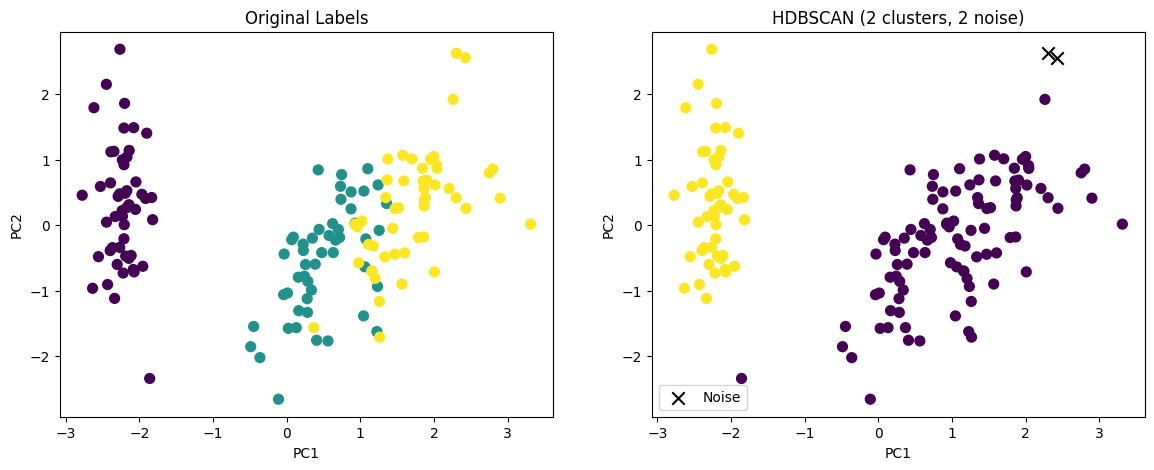

In [4]:
X_pca = PCA(n_components=2).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='viridis', s=50)
axes[0].set_title('Original Labels')

noise = labels == -1
sc = axes[1].scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=labels[~noise], cmap='viridis', s=50)
axes[1].scatter(X_pca[noise, 0], X_pca[noise, 1], c='black', marker='x', s=80, label='Noise')
axes[1].set_title(f'HDBSCAN ({n_clusters} clusters, {n_noise} noise)')
axes[1].legend()

for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.show()

## 4. Comparison with the Original Labels

In [5]:
pd.crosstab(pd.Series(iris.target_names[y_true], name='Original label'),
            pd.Series(labels, name='HDBSCAN cluster'))

HDBSCAN cluster,-1,0,1
Original label,,,
setosa,0,1,49
versicolor,0,50,0
virginica,2,48,0


HDBSCAN identifies 2 clusters (ARI approx 0.54): setosa forms a distinct group, while overlapping versicolor and virginica merge into a second. It captures the data's true density structure rather than the 3 original species (counts vary by min_cluster_size).